<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/05_entrenamiento_E3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E3 — ResNet50 congelada

Clasificación de enfermedades de la yuca mediante extracción de características. Comparación principal: E1 frente a E3. Se mantiene el protocolo de E1 y se reserva test para la evaluación final.


## 1. Entorno y reproducibilidad

In [8]:
%pip -q install tensorflow-datasets importlib_resources psutil

In [9]:
import os, time, gc, json, platform, subprocess
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import psutil

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
EPOCHS = 7
NUM_CLASSES = 5
LR = 1e-3
CLASS_NAMES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
OUTPUT_DIR = "results/e3"
os.makedirs(OUTPUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"RAM disponible: {psutil.virtual_memory().available/1024**3:.2f} GB")
print("Python:", platform.python_version())
if tf.config.list_physical_devices("GPU"):
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], check=False)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM disponible: 9.52 GB
Python: 3.13.16


## 2. Manifiesto depurado y particiones idénticas a E1

In [10]:
URL_MANIFIESTO = (
    "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/"
    "main/results/eda/manifiesto_final_conservados.csv"
)
df_manifest = pd.read_csv(URL_MANIFIESTO)
assert {"particion", "indice"}.issubset(df_manifest.columns)
assert len(df_manifest) == 9361
assert not df_manifest.duplicated(["particion", "indice"]).any()
print(df_manifest.groupby("particion").size())

particion
test          1874
train         5610
validation    1877
dtype: int64


In [11]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava:0.1.0",
    split=["train", "validation", "test"],
    as_supervised=True, with_info=True, shuffle_files=False
)

def aplicar_manifiesto(ds, particion):
    total = int(tf.data.experimental.cardinality(ds).numpy())
    indices = set(df_manifest.loc[
        df_manifest["particion"] == particion, "indice"
    ].astype(int))
    assert indices and min(indices) >= 0 and max(indices) < total
    mascara = tf.constant([i in indices for i in range(total)], dtype=tf.bool)
    filtrado = (ds.enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato, num_parallel_calls=1))
    return filtrado.apply(tf.data.experimental.assert_cardinality(len(indices)))

ds_train_final = aplicar_manifiesto(ds_train, "train")
ds_val_final = aplicar_manifiesto(ds_val, "validation")
ds_test_final = aplicar_manifiesto(ds_test, "test")
n_train, n_val, n_test = (
    int(tf.data.experimental.cardinality(ds).numpy())
    for ds in (ds_train_final, ds_val_final, ds_test_final)
)
assert (n_train, n_val, n_test) == (5610, 1877, 1874)
print("Train:", n_train, "| Validación:", n_val, "| Test reservado:", n_test)

Train: 5610 | Validación: 1877 | Test reservado: 1874


## 3. Pipeline de datos con RAM limitada

In [12]:
def preprocesar(imagen, etiqueta):
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen, tf.cast(etiqueta, tf.int32)

train_ds = (ds_train_final
    .shuffle(512, seed=SEED, reshuffle_each_iteration=True)
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))
val_ds = (ds_val_final
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))

x_batch, y_batch = next(iter(train_ds))
print("Batch:", x_batch.shape, x_batch.dtype, y_batch.shape)
print("Rango:", float(tf.reduce_min(x_batch)), float(tf.reduce_max(x_batch)))
assert x_batch.shape == (BATCH_SIZE, 224, 224, 3)
assert 0 <= float(tf.reduce_min(x_batch)) <= float(tf.reduce_max(x_batch)) <= 255
del x_batch, y_batch
gc.collect()

Batch: (8, 224, 224, 3) <dtype: 'float32'> (8,)
Rango: 0.0 255.0


756

## 4. Modelo E3: ResNet50 congelada

In [13]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

base = ResNet50(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

entradas = layers.Input(shape=(*IMG_SIZE, 3), name="imagen_0_255")
# RGB → BGR y resta de medias ImageNet; capas serializables.
x = layers.Conv2D(3, 1, trainable=False, name="preprocesamiento_resnet50")(entradas)
modelo_pre = Model(entradas, x)
modelo_pre.get_layer("preprocesamiento_resnet50").set_weights([
    np.array([[ [[0,0,1],[0,1,0],[1,0,0]] ]], dtype=np.float32),
    np.array([-103.939, -116.779, -123.68], dtype=np.float32)
])
prueba = tf.constant([[[[10., 20., 30.]]]])
np.testing.assert_allclose(modelo_pre(tf.broadcast_to(prueba, (1,224,224,3))).numpy(),
    tf.keras.applications.resnet50.preprocess_input(tf.broadcast_to(prueba, (1,224,224,3))).numpy(), atol=1e-5)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salidas = layers.Dense(NUM_CLASSES, activation="softmax")(x)
modelo_e3 = Model(entradas, salidas, name="ResNet50_E3")
modelo_e3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
params_entrenables = sum(int(np.prod(w.shape)) for w in modelo_e3.trainable_weights)
params_totales = modelo_e3.count_params()
assert not base.trainable and all(not capa.trainable for capa in base.layers)
print("Parámetros entrenables:", params_entrenables)
print("Parámetros totales:", params_totales)
modelo_e3.summary()

Parámetros entrenables: 262917
Parámetros totales: 23850641


Model: "ResNet50_E3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_0_255 (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento_resnet50       │ (None, 224, 224, 3)    │            12 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,641 (90.98 MB)

 Trainable params: 262,917 (1.00 MB)

 Non-trainable params: 23,587,724 (89.98 MB)

## 5. Entrenamiento y monitoreo de RAM

In [14]:
class MonitorMemoria(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mem = psutil.virtual_memory()
        print(f"RAM al terminar época {epoch+1}: {mem.percent:.1f}% "
              f"| disponible {mem.available/1024**3:.2f} GB")

callbacks_e3 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(OUTPUT_DIR, "mejor_modelo_e3.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(OUTPUT_DIR, "historial_entrenamiento.csv")
    ),
    MonitorMemoria(),
]

inicio = time.perf_counter()
historial_e3 = modelo_e3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_e3,
    verbose=1
)
tiempo_entrenamiento_e3 = time.perf_counter() - inicio
print(f"Tiempo: {tiempo_entrenamiento_e3:.2f} s")
print("Épocas ejecutadas:", len(historial_e3.history["loss"]))

Epoch 1/7
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6376 - loss: 1.0396RAM al terminar época 1: 28.2% | disponible 9.10 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 80s 76ms/step - accuracy: 0.6724 - loss: 0.8988 - val_accuracy: 0.7597 - val_loss: 0.6895
Epoch 2/7
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7276 - loss: 0.7362RAM al terminar época 2: 33.2% | disponible 8.46 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 31s 43ms/step - accuracy: 0.7414 - loss: 0.7099 - val_accuracy: 0.7608 - val_loss: 0.6863
Epoch 3/7
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7552 - loss: 0.6673RAM al terminar época 3: 33.9% | disponible 8.38 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.7613 - loss: 0.6454 - val_accuracy: 0.7869 - val_loss: 0.6196
Epoch 4/7
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7878 - loss: 0.5846RAM al terminar época 4: 32.4% | disponible 8.57 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 31s 42ms/step - accuracy: 0.7936 - loss: 0.5672 - val_accuracy: 0.

## 6. Evaluación de validación (sin usar test)

In [15]:
modelo_e3 = tf.keras.models.load_model(os.path.join(OUTPUT_DIR, "mejor_modelo_e3.keras"), compile=False)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for _, y in val_ds])
assert len(y_true) == n_val

_ = modelo_e3.predict(val_ds.take(2), verbose=0)
inicio = time.perf_counter()
probabilidades = modelo_e3.predict(val_ds, verbose=0)
tiempo_inferencia_e3 = time.perf_counter() - inicio
assert probabilidades.shape == (n_val, NUM_CLASSES)
y_pred = probabilidades.argmax(axis=1)

accuracy_e3 = accuracy_score(y_true, y_pred)
macro_f1_e3 = f1_score(y_true, y_pred, average="macro", labels=range(NUM_CLASSES), zero_division=0)
ms_por_imagen = tiempo_inferencia_e3 / n_val * 1000
print(f"Accuracy: {accuracy_e3:.4f}")
print(f"Macro-F1: {macro_f1_e3:.4f}")
print(f"Inferencia: {ms_por_imagen:.2f} ms/imagen")
print(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, zero_division=0
))

Accuracy: 0.7896
Macro-F1: 0.7152
Inferencia: 6.26 ms/imagen
              precision    recall  f1-score   support

         cbb       0.68      0.46      0.55       151
        cbsd       0.76      0.78      0.77       479
         cgm       0.69      0.67      0.68       257
         cmd       0.85      0.90      0.87       885
     healthy       0.78      0.65      0.71       105

    accuracy                           0.79      1877
   macro avg       0.75      0.69      0.72      1877
weighted avg       0.78      0.79      0.78      1877



## 7. Guardar métricas y gráficas

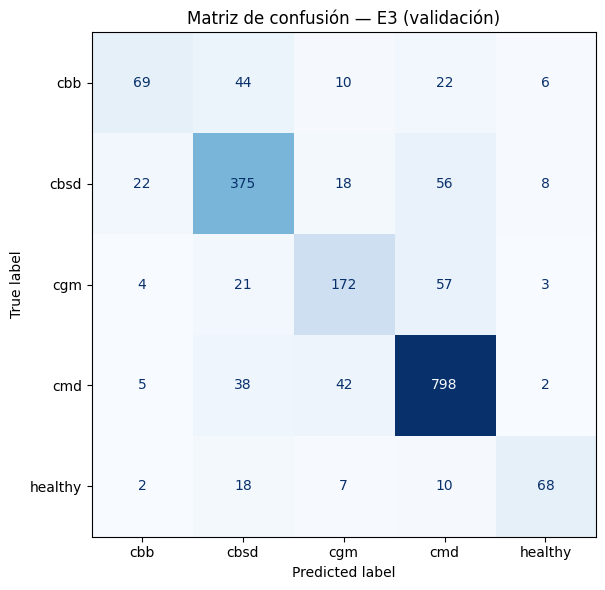

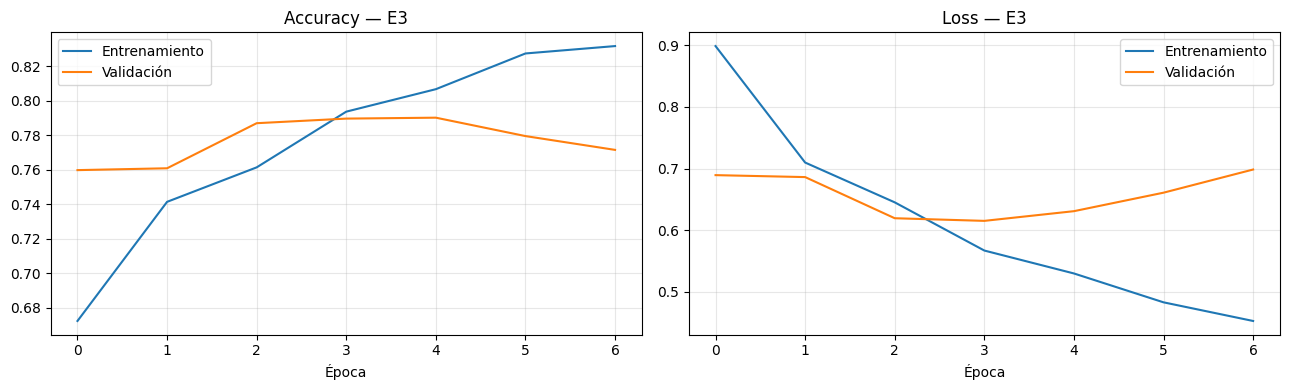

Archivos: ['reporte_clasificacion.csv', 'matriz_confusion.png', 'matriz_confusion.csv', 'mejor_modelo_e3.keras', 'resumen_metricas.csv', 'curvas_entrenamiento.png', 'historial_entrenamiento.csv']


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

reporte = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
pd.DataFrame(reporte).T.to_csv(os.path.join(OUTPUT_DIR, "reporte_clasificacion.csv"))
matriz = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
pd.DataFrame(matriz, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    os.path.join(OUTPUT_DIR, "matriz_confusion.csv")
)

ruta_modelo = os.path.join(OUTPUT_DIR, "mejor_modelo_e3.keras")
tamano_mb = os.path.getsize(ruta_modelo) / (1024**2)
pd.DataFrame([{
    "modelo": "E3_ResNet50_congelada",
    "accuracy": accuracy_e3,
    "macro_f1": macro_f1_e3,
    "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e3,
    "epocas_ejecutadas": len(historial_e3.history["loss"]),
    "segundos_por_epoca": tiempo_entrenamiento_e3 / len(historial_e3.history["loss"]),
    "ms_inferencia_por_imagen": ms_por_imagen,
    "tamano_modelo_MB": tamano_mb,
    "parametros_entrenables": params_entrenables,
    "parametros_totales": params_totales,
    "batch_size": BATCH_SIZE,
    "resolucion": f"{IMG_SIZE[0]}x{IMG_SIZE[1]}",
    "learning_rate": LR,
    "semilla": SEED,
}]).to_csv(os.path.join(OUTPUT_DIR, "resumen_metricas.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(matriz, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Matriz de confusión — E3 (validación)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "matriz_confusion.png"), dpi=200)
plt.show()
plt.close(fig)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, clave, titulo in zip(ejes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(historial_e3.history[clave], label="Entrenamiento")
    ax.plot(historial_e3.history["val_" + clave], label="Validación")
    ax.set(xlabel="Época", title=f"{titulo} — E3")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "curvas_entrenamiento.png"), dpi=200)
plt.show()
plt.close(fig)
print("Archivos:", os.listdir(OUTPUT_DIR))
np.savez_compressed(os.path.join(OUTPUT_DIR, "predicciones_validacion.npz"), y_true=y_true, y_pred=y_pred, probabilidades=probabilidades)
with open(os.path.join(OUTPUT_DIR, "entorno.json"), "w") as f:
    json.dump({"python": platform.python_version(), "tensorflow": tf.__version__, "tfds": tfds.__version__, "gpu": [tf.config.experimental.get_device_details(g).get("device_name", g.name) for g in tf.config.list_physical_devices("GPU")]}, f, indent=2)

## 8. Comparación E1 frente a E3 (validación)

In [17]:
URL_E1 = "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/main/results/e1/resumen_metricas.csv"
try:
    e1 = pd.read_csv(URL_E1)
except Exception as error:
    print("No se pudo cargar el CSV de E1:", error)
    e1 = pd.DataFrame([{"modelo": "E1_MobileNetV2", "accuracy": 0.7645, "macro_f1": 0.6777, "tiempo_entrenamiento_segundos": 286.50}])
e3 = pd.read_csv(os.path.join(OUTPUT_DIR, "resumen_metricas.csv"))
columnas = ["modelo", "accuracy", "macro_f1", "tiempo_entrenamiento_segundos"]
comparacion = pd.concat([e1[columnas], e3[columnas]], ignore_index=True)
print(comparacion.to_string(index=False))
comparacion.to_csv(os.path.join(OUTPUT_DIR, "comparacion_e1_e3.csv"), index=False)

                  modelo  accuracy  macro_f1  tiempo_entrenamiento_segundos
E1_MobileNetV2_congelada  0.764518  0.677748                     286.504443
   E3_ResNet50_congelada  0.789558  0.715189                     294.627189


## 9. Inspección de ocho errores (sin cargar todas las imágenes)

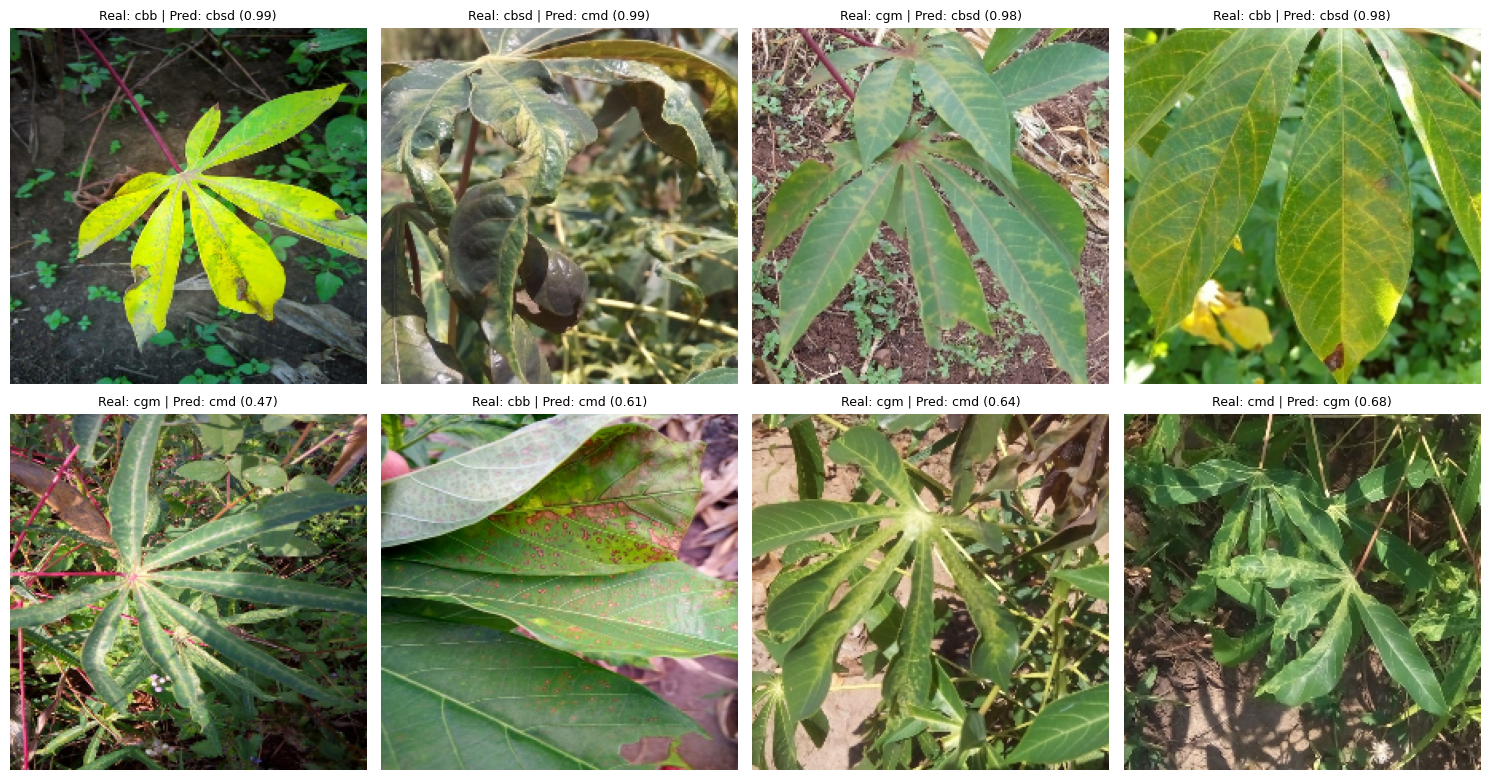

10907

In [18]:
indices_error = np.flatnonzero(y_pred != y_true)
confianza = probabilidades.max(axis=1)
assert len(indices_error) >= 8, "Se necesitan al menos ocho errores para esta inspección"

rng = np.random.default_rng(SEED)
altos = indices_error[np.argsort(-confianza[indices_error])[:4]]
restantes = np.setdiff1d(indices_error, altos)
aleatorios = rng.choice(restantes, size=4, replace=False)
seleccion = np.concatenate([altos, aleatorios])

objetivos = set(int(i) for i in seleccion)
imagenes = {}
posicion = 0
for lote_x, _ in val_ds:
    for img in lote_x:
        if posicion in objetivos:
            imagenes[posicion] = np.clip(img.numpy(), 0, 255).astype(np.uint8)
        posicion += 1
    if len(imagenes) == len(objetivos):
        break
assert len(imagenes) == 8

fig, ejes = plt.subplots(2, 4, figsize=(15, 8))
for ax, indice in zip(ejes.flat, seleccion):
    indice = int(indice)
    ax.imshow(imagenes[indice])
    ax.set_title(f"Real: {CLASS_NAMES[y_true[indice]]} | "
                 f"Pred: {CLASS_NAMES[y_pred[indice]]} ({confianza[indice]:.2f})", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "errores_inspeccionados.png"), dpi=180)
plt.show()
plt.close(fig)

pd.DataFrame({
    "indice_validacion": seleccion,
    "clase_real": [CLASS_NAMES[y_true[i]] for i in seleccion],
    "clase_predicha": [CLASS_NAMES[y_pred[i]] for i in seleccion],
    "confianza": confianza[seleccion],
}).to_csv(os.path.join(OUTPUT_DIR, "errores_inspeccionados.csv"), index=False)
del imagenes
gc.collect()